In [493]:
K = 5
L = 0
g = 3
HOP = 2048

In [494]:
"""HNMA: Harmonic/shift-regularized non-negative matrix factorization.

Implements the shift-similarity penalty shown in the supplied paper:

    alpha(W) = ||W - S_D W S_R||_F^2

where S_D shifts frequency bins down by one semitone and S_R shifts basis
columns to the right by one. The factorization convention is X ~= W @ H,
with X=(frequency, time), W=(frequency, components), H=(components, time).

The multiplicative updates use a split-gradient rule for regularizer gradients,
so signed gradients do not get inserted directly into a multiplicative
update's denominator. A column-simplex normalization of W is enabled by
default; it removes the W/H scale ambiguity and is required for the log-det
volume option to have a well-behaved scale.

Dependencies: NumPy only.
"""

from __future__ import annotations

from typing import Optional, Literal, Union
import warnings
import numpy as np
np.random.seed(42)
ArrayLike = Union[np.ndarray, list]


class HNMA:
    """Harmonic/shift-regularized NMF with optional H sparsity and volume term.

    Parameters
    ----------
    n_components : int, optional
        Number of basis vectors. If omitted, it is inferred from W_init or
        H_init passed to fit/fit_transform.
    lambda_h : float, default=0.0
        L1 sparsity penalty on H: lambda_h * ||H||_1. Must be non-negative.
    lambda_shift : float, default=0.0
        Strength of the HNMA shift penalty ||W - S_D W S_R||_F^2.
        Must be non-negative.
    lambda_volume : float, default=0.0
        Non-negative magnitude of the log-determinant volume regularizer.
        Its sign is controlled by volume_mode.
    volume_mode : {'none', 'min', 'max'}, default='none'
        'min' adds +0.5 * lambda_volume * logdet(W.T W + 11.T + delta I).
        'max' adds the negative of this term. 'max' encourages more spread-out
        basis columns, but is non-convex and can be sensitive to initialization.
    sparsity_measure : {'l1', 'none'}, default='l1'
        Sparsity penalty applied to H. Use 'none' to disable it regardless of
        lambda_h. The L1 penalty is the one handled by the MU update here.
    bins_per_octave : int, default=36
        Frequency-grid resolution used to derive the semitone shift. For a
        36-bin/octave CQT (3 bins per semitone), the shift is 3 frequency bins.
        For a 12-bin/octave grid, it is 1.
    shift_bins : int, optional
        Explicit number of frequency bins for the downward shift. Overrides
        bins_per_octave-derived value.
    normalize_W : bool, default=True
        Normalize each W column to sum to one after updates, rescaling H to
        preserve W@H. Required when volume_mode is 'min' or 'max'.
    max_iter : int, default=300
        Maximum number of alternating multiplicative-update iterations.
    tol : float, default=1e-5
        Stop when relative objective change is small for several iterations.
    min_iter : int, default=10
        Minimum iterations before convergence checking.
    patience : int, default=5
        Number of consecutive small objective changes needed to stop.
    epsilon : float, default=1e-10
        Numerical floor for non-negative variables and update denominators.
    volume_delta : float, default=1e-6
        Diagonal jitter in the log-determinant matrix.
    random_state : int or None, default=None
        Seed for initialization.
    verbose : bool, default=False
        Print objective and relative-change information periodically.
    eval_every : int, default=1
        Evaluate the full objective every this many iterations. Convergence
        checks are made only on evaluated iterations.

    Notes
    -----
    The algorithm is non-convex. The max-volume option uses a sign-reversed
    log-det surrogate, not a guarantee of globally maximum-volume NMF. Check
    reconstruction, regularization values, and downstream transcription
    quality when tuning the coefficients.
    """

    def __init__(
        self,
        n_components: Optional[int] = None,
        *,
        lambda_h: float = 0.0,
        lambda_shift: float = 0.0,
        lambda_volume: float = 0.0,
        volume_mode: Literal["none", "min", "max"] = "none",
        sparsity_measure: Literal["l1", "none"] = "l1",
        bins_per_octave: int = 36,
        shift_bins: Optional[int] = None,
        normalize_W: bool = True,
        max_iter: int = 300,
        tol: float = 1e-5,
        min_iter: int = 10,
        patience: int = 5,
        epsilon: float = 1e-10,
        volume_delta: float = 1e-6,
        random_state: Optional[int] = None,
        verbose: bool = False,
        eval_every: int = 1,
    ):
        if n_components is not None and n_components <= 0:
            raise ValueError("n_components must be a positive integer or None.")
        if lambda_h < 0 or lambda_shift < 0 or lambda_volume < 0:
            raise ValueError("lambda_h, lambda_shift, and lambda_volume must be non-negative.")
        if volume_mode not in {"none", "min", "max"}:
            raise ValueError("volume_mode must be 'none', 'min', or 'max'.")
        if sparsity_measure not in {"l1", "none"}:
            raise ValueError("sparsity_measure must be 'l1' or 'none'.")
        if bins_per_octave <= 0:
            raise ValueError("bins_per_octave must be positive.")
        if shift_bins is None:
            if bins_per_octave % 12 != 0:
                raise ValueError(
                    "bins_per_octave must be divisible by 12, or provide shift_bins explicitly."
                )
            shift_bins = bins_per_octave // 12
        if shift_bins <= 0:
            raise ValueError("shift_bins must be a positive integer.")
        if volume_mode != "none" and not normalize_W:
            raise ValueError("normalize_W=True is required for the log-det volume term.")
        if max_iter <= 0 or min_iter < 0 or patience <= 0 or eval_every <= 0:
            raise ValueError("max_iter, patience, eval_every must be positive and min_iter non-negative.")
        if tol < 0 or epsilon <= 0 or volume_delta <= 0:
            raise ValueError("tol must be non-negative; epsilon and volume_delta must be positive.")

        self.n_components = n_components
        self.lambda_h = float(lambda_h) if sparsity_measure == "l1" else 0.0
        self.lambda_shift = float(lambda_shift)
        self.lambda_volume = float(lambda_volume)
        self.volume_mode = volume_mode
        self.sparsity_measure = sparsity_measure
        self.bins_per_octave = int(bins_per_octave)
        self.shift_bins = int(shift_bins)
        self.normalize_W = bool(normalize_W)
        self.max_iter = int(max_iter)
        self.tol = float(tol)
        self.min_iter = int(min_iter)
        self.patience = int(patience)
        self.epsilon = float(epsilon)
        self.volume_delta = float(volume_delta)
        self.random_state = random_state
        self.verbose = bool(verbose)
        self.eval_every = int(eval_every)

        self.components_: Optional[np.ndarray] = None  # W
        self.activations_: Optional[np.ndarray] = None  # H
        self.reconstruction_: Optional[np.ndarray] = None
        self.objective_history_: list[float] = []
        self.n_iter_: int = 0
        self.n_features_in_: Optional[int] = None
        self.n_frames_in_: Optional[int] = None
        self.converged_: bool = False

    def _validate_X(self, X: ArrayLike) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2:
            raise ValueError("X must be a 2D matrix with shape (frequency_bins, time_frames).")
        if X.shape[0] == 0 or X.shape[1] == 0:
            raise ValueError("X must have at least one frequency bin and one time frame.")
        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinite values.")
        if np.any(X < 0):
            raise ValueError("NMF requires X >= 0. Pass a non-negative magnitude or power spectrogram.")
        return X

    def _infer_rank(
        self,
        W_init: Optional[ArrayLike],
        H_init: Optional[ArrayLike],
    ) -> int:
        inferred = []
        if W_init is not None:
            w = np.asarray(W_init)
            if w.ndim != 2:
                raise ValueError("W_init must be 2D with shape (frequency_bins, components).")
            inferred.append(w.shape[1])
        if H_init is not None:
            h = np.asarray(H_init)
            if h.ndim != 2:
                raise ValueError("H_init must be 2D with shape (components, time_frames).")
            inferred.append(h.shape[0])
        if inferred and any(k != inferred[0] for k in inferred):
            raise ValueError("W_init and H_init disagree on the number of components.")
        if self.n_components is not None and inferred and self.n_components != inferred[0]:
            raise ValueError("n_components does not match W_init/H_init shapes.")
        if self.n_components is not None:
            return int(self.n_components)
        if inferred:
            return int(inferred[0])
        raise ValueError("Set n_components or provide W_init/H_init so rank can be inferred.")

    def _normalize_columns(
        self,
        W: np.ndarray,
        H: Optional[np.ndarray] = None,
    ):
        sums = np.sum(W, axis=0)
        sums = np.maximum(sums, self.epsilon)
        W /= sums[None, :]
        if H is not None:
            H *= sums[:, None]
        return W, H

    def _initialize(
        self,
        X: np.ndarray,
        W_init: Optional[ArrayLike],
        H_init: Optional[ArrayLike],
    ):
        F, T = X.shape
        K = self._infer_rank(W_init, H_init)
        rng = np.random.default_rng(self.random_state)

        if W_init is not None:
            W = np.asarray(W_init, dtype=np.float64).copy()
            if W.shape != (F, K):
                raise ValueError(f"W_init must have shape {(F, K)}, got {W.shape}.")
            if not np.all(np.isfinite(W)) or np.any(W < 0):
                raise ValueError("W_init must be finite and non-negative.")
            W = np.maximum(W, self.epsilon)
        else:
            # Random positive initialization with a mild data-dependent scale.
            W = rng.random((F, K)) + 0.1
            W = np.maximum(W, self.epsilon)

        if H_init is not None:
            H = np.asarray(H_init, dtype=np.float64).copy()
            if H.shape != (K, T):
                raise ValueError(f"H_init must have shape {(K, T)}, got {H.shape}.")
            if not np.all(np.isfinite(H)) or np.any(H < 0):
                raise ValueError("H_init must be finite and non-negative.")
            H = np.maximum(H, self.epsilon)
        else:
            H = None

        if self.normalize_W:
            W, H = self._normalize_columns(W, H)

        if H is None:
            # A non-negative least-squares-like warm start.
            H = np.maximum(W.T @ X, self.epsilon)
            denom = (W.T @ W @ H) + self.epsilon
            H *= (W.T @ X + self.epsilon) / denom
        return W, H

    def _shifted_down_right(self, W: np.ndarray) -> np.ndarray:
        """Compute S_D @ W @ S_R using zero-filled shifts."""
        q = self.shift_bins
        shifted = np.zeros_like(W)
        if q < W.shape[0] and W.shape[1] > 1:
            shifted[q:, 1:] = W[:-q, :-1]
        return shifted

    def _shift_gradient(self, W: np.ndarray) -> np.ndarray:
        """Gradient of lambda_shift * ||W - S_D W S_R||_F^2."""
        D = W - self._shifted_down_right(W)
        # Apply the adjoint of the two-dimensional down/right shift:
        # (S_D.T @ D @ S_R.T)[i,j] = D[i+shift_bins, j+1].
        adjoint = np.zeros_like(D)
        q = self.shift_bins
        if q < W.shape[0] and W.shape[1] > 1:
            adjoint[:-q, :-1] = D[q:, 1:]
        return 2.0 * self.lambda_shift * (D - adjoint)

    def _volume_sign(self) -> float:
        if self.volume_mode == "min":
            return 1.0
        if self.volume_mode == "max":
            return -1.0
        return 0.0

    def _volume_gradient(self, W: np.ndarray) -> np.ndarray:
        sign = self._volume_sign()
        if sign == 0.0 or self.lambda_volume == 0.0:
            return np.zeros_like(W)
        K = W.shape[1]
        ones_outer = np.ones((K, K), dtype=W.dtype)
        G = W.T @ W + ones_outer + self.volume_delta * np.eye(K)
        # Solve rather than explicitly inverting G: W @ inv(G).
        try:
            solved = np.linalg.solve(G, W.T).T
        except np.linalg.LinAlgError:
            G = G + (10.0 * self.volume_delta) * np.eye(K)
            solved = np.linalg.solve(G, W.T).T
        return sign * self.lambda_volume * solved

    def _regularizer_gradient_W(self, W: np.ndarray) -> np.ndarray:
        return self._shift_gradient(W) + self._volume_gradient(W)

    def _objective(self, X: np.ndarray, W: np.ndarray, H: np.ndarray) -> float:
        residual = X - W @ H
        value = 0.5 * float(np.sum(residual * residual))

        if self.lambda_h:
            value += self.lambda_h * float(np.sum(H))

        if self.lambda_shift:
            D = W - self._shifted_down_right(W)
            value += self.lambda_shift * float(np.sum(D * D))

        if self.lambda_volume and self.volume_mode != "none":
            K = W.shape[1]
            G = W.T @ W + np.ones((K, K)) + self.volume_delta * np.eye(K)
            sign_det, logdet = np.linalg.slogdet(G)
            if sign_det <= 0 or not np.isfinite(logdet):
                return float("inf")
            value += 0.5 * self._volume_sign() * self.lambda_volume * float(logdet)

        return value

    @staticmethod
    def _positive_part(A: np.ndarray) -> np.ndarray:
        return np.maximum(A, 0.0)

    @staticmethod
    def _negative_part(A: np.ndarray) -> np.ndarray:
        return np.maximum(-A, 0.0)

    def fit(
        self,
        X: ArrayLike,
        *,
        W_init: Optional[ArrayLike] = None,
        H_init: Optional[ArrayLike] = None,
    ) -> "HNMA":
        """Factorize X and store basis W in components_ and activations H."""
        X = self._validate_X(X)
        F, T = X.shape
        W, H = self._initialize(X, W_init, H_init)
        K = W.shape[1]

        numerator_H_base = W.T @ X
        self.objective_history_ = []
        small_change_count = 0
        previous_obj = None
        self.converged_ = False

        for iteration in range(1, self.max_iter + 1):
            # Update H: standard sparse-NMF multiplicative update.
            numerator_H = W.T @ X
            denominator_H = (W.T @ W) @ H + self.lambda_h + self.epsilon
            H *= (numerator_H + self.epsilon) / denominator_H
            np.maximum(H, self.epsilon, out=H)

            # Update W using a split-gradient MU rule:
            # W <- W * (XH.T + [grad_reg]_-)/(WHH.T + [grad_reg]_+).
            numerator_W_base = X @ H.T
            denominator_W_base = W @ (H @ H.T)
            grad_reg = self._regularizer_gradient_W(W)
            numerator_W = numerator_W_base + self._negative_part(grad_reg)
            denominator_W = denominator_W_base + self._positive_part(grad_reg) + self.epsilon
            W *= (numerator_W + self.epsilon) / denominator_W
            np.maximum(W, self.epsilon, out=W)

            # Remove W/H scale ambiguity while preserving W@H.
            if self.normalize_W:
                W, H = self._normalize_columns(W, H)

            if iteration % self.eval_every == 0 or iteration == self.max_iter:
                obj = self._objective(X, W, H)
                self.objective_history_.append(obj)
                rel_change = None
                if previous_obj is not None:
                    rel_change = abs(previous_obj - obj) / max(abs(previous_obj), self.epsilon)
                    if rel_change < self.tol:
                        small_change_count += 1
                    else:
                        small_change_count = 0
                if self.verbose:
                    change_str = "n/a" if rel_change is None else f"{rel_change:.3e}"
                    print(
                        f"HNMA iteration {iteration:4d}/{self.max_iter}: "
                        f"objective={obj:.8e}, relative_change={change_str}"
                    )
                if (
                    iteration >= self.min_iter
                    and small_change_count >= self.patience
                ):
                    self.converged_ = True
                    self.n_iter_ = iteration
                    break
                previous_obj = obj
        else:
            self.n_iter_ = self.max_iter

        self.components_ = W
        self.activations_ = H
        self.reconstruction_ = W @ H
        self.n_features_in_ = F
        self.n_frames_in_ = T
        return self

    def fit_transform(
        self,
        X: ArrayLike,
        *,
        W_init: Optional[ArrayLike] = None,
        H_init: Optional[ArrayLike] = None,
    ) -> np.ndarray:
        """Fit the factorization and return H."""
        self.fit(X, W_init=W_init, H_init=H_init)
        return self.activations_.copy()

    def transform(
        self,
        X: ArrayLike,
        *,
        H_init: Optional[ArrayLike] = None,
        max_iter: Optional[int] = None,
    ) -> np.ndarray:
        """Estimate activations H for a new X while keeping the learned W fixed.

        Only the L1 sparsity penalty on H is active here; W-specific shift and
        volume penalties were handled during fit and are not re-optimized.
        """
        if self.components_ is None:
            raise RuntimeError("Call fit before transform.")
        X = self._validate_X(X)
        W = self.components_
        if X.shape[0] != W.shape[0]:
            raise ValueError("X frequency dimension must match fitted W.")
        K, T = W.shape[1], X.shape[1]
        if H_init is not None:
            H = np.asarray(H_init, dtype=np.float64).copy()
            if H.shape != (K, T):
                raise ValueError(f"H_init must have shape {(K, T)}.")
            if not np.all(np.isfinite(H)) or np.any(H < 0):
                raise ValueError("H_init must be finite and non-negative.")
            H = np.maximum(H, self.epsilon)
        else:
            H = np.maximum(W.T @ X, self.epsilon)

        steps = self.max_iter if max_iter is None else int(max_iter)
        if steps <= 0:
            raise ValueError("max_iter must be positive.")
        WT_X = W.T @ X
        WT_W = W.T @ W
        for _ in range(steps):
            H *= (WT_X + self.epsilon) / (WT_W @ H + self.lambda_h + self.epsilon)
            np.maximum(H, self.epsilon, out=H)
        return H


def hnma(
    X: ArrayLike,
    n_components: Optional[int] = None,
    *,
    W_init: Optional[ArrayLike] = None,
    H_init: Optional[ArrayLike] = None,
    **kwargs,
):
    """Convenience function returning (W, H, fitted_model)."""
    model = HNMA(n_components=n_components, **kwargs)
    H = model.fit_transform(X, W_init=W_init, H_init=H_init)
    return model.components_.copy(), H, model


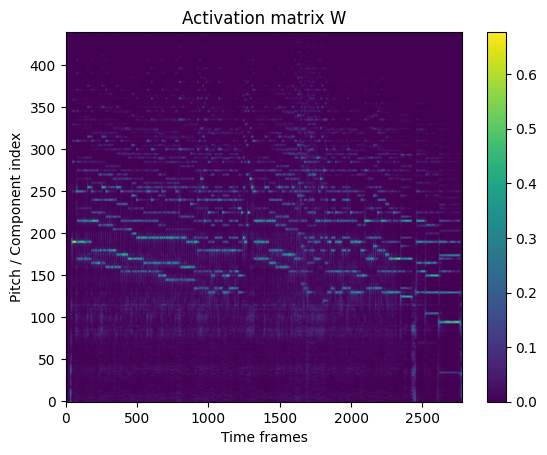

In [495]:
from scipy.io import wavfile
import librosa
import numpy as np

file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K+L, hop_length=HOP, sparsity=0.05))
#spectrogram_1 = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
onsets = librosa.onset.onset_detect(y=x, sr=f_s, hop_length=HOP,units='frames')
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
spectrogram = norm_log(spectrogram, g)
spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

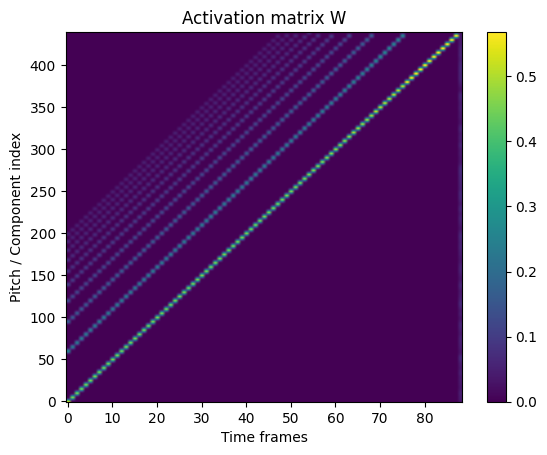

In [496]:
def build_W0(
    sr,
    bins_per_octave,
    n_bins,
    fmin,
    n_harmonics=10,
    decay=1.0,
    sigma=1.5,
    inharmonicity=0.0,
):
    # CQT frequency grid: must match your spectrogram
    freqs = librosa.cqt_frequencies(
        n_bins=n_bins,
        fmin=fmin,
        bins_per_octave=bins_per_octave,
    )

    # Log-frequency coordinates corresponding to CQT bins
    log_freqs = np.log2(freqs)
    k = np.arange(n_bins, dtype=float)

    # Piano pitches: MIDI 21 (A0) through MIDI 108 (C8)
    midi_notes = np.arange(21, 109)

    W0 = np.zeros((n_bins, len(midi_notes)), dtype=float)

    f_max = min(freqs[-1], sr / 2.0)

    for i, m in enumerate(midi_notes):
        f0 = librosa.midi_to_hz(m)
        template = np.zeros(n_bins, dtype=float)

        for h in range(1, n_harmonics + 1):

            # Harmonic frequency, optionally including piano
            # string inharmonicity.
            fh = h * f0 * np.sqrt(
                (1.0 + inharmonicity * h**2)
                / (1.0 + inharmonicity)
            )

            # CRITICAL FIX:
            # Never map out-of-range harmonics onto the
            # first or last CQT bin.
            if fh >= f_max:
                break

            if fh < freqs[0]:
                continue

            # Fractional bin coordinate in log-frequency space
            center = np.interp(
                np.log2(fh),
                log_freqs,
                k,
            )

            # Gaussian harmonic peak
            peak = np.exp(
                -0.5 * ((k - center) / sigma) ** 2
            )

            template += peak / (h ** decay)

        # L2 normalization
        norm = np.linalg.norm(template)
        if norm > 1e-10:
            template /= norm

        W0[:, i] = template

    return W0

def build_noise_basis(n_bins, n_components=2):
    Wn = np.zeros((n_bins, n_components))

    for i in range(n_components):
        # random smooth noise shape
        x = np.random.rand(n_bins)
        x = np.convolve(x, np.hanning(15), mode='same')
        x /= np.linalg.norm(x) + 1e-10
        Wn[:, i] = x

    return Wn
W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K+L, fmin=librosa.note_to_hz('A0'), sigma=1.75)
#W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=2.0)
Wn = build_noise_basis(88*K+L, 1)
W_0 = np.concatenate([W_0, Wn], axis=1)
#W_0 = W_norm(W_0)
#print(W_0.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_0, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [497]:
W, H, history = hnma(
    spectrogram,
    W_init=W_0,
    n_components=88+1,
    lambda_h=1e-3,
    #lambda_shift=0.1,
    #shift_bins=0,
    #lambda_volume=1e-3,
    #volume_delta=1e-6,
    #volume_mode = "max",
    bins_per_octave=12*K,
    max_iter=500,
    tol=1e-5,
    random_state=42,
)

V_hat = W @ H

print("W:", W.shape)
print("H:", H.shape)


W: (440, 89)
H: (89, 2781)


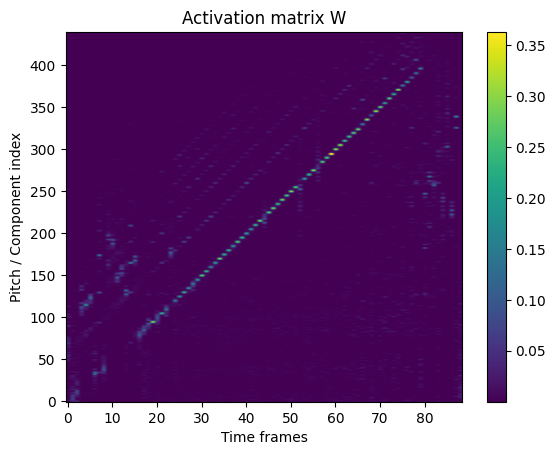

In [498]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

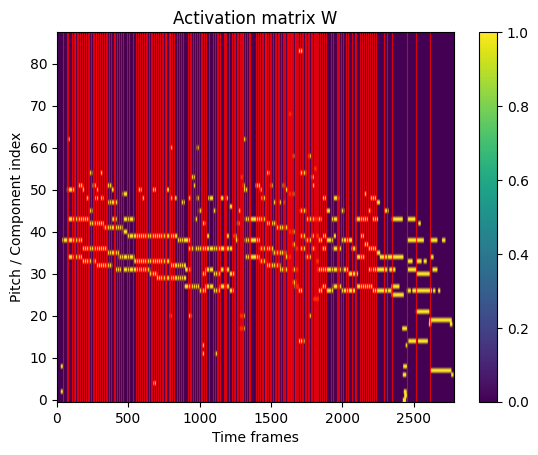

In [499]:
import scipy
from scipy.ndimage import label
def med_filter(X, sz=5):
  X_r = np.zeros(X.shape)
  for i in range(X.shape[0]):
    X_r[i,:] = scipy.ndimage.median_filter(X[i,:], size=sz, cval=0, mode='constant')
  return X_r

def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B

H1 = med_filter(H,sz=9)
#H1 = med_filter(H)
H2 = np.zeros_like(H1)
idx = np.argpartition(H1, -10, axis=0)[-10:, :]
H2[idx, np.arange(H1.shape[1])] = H1[idx, np.arange(H1.shape[1])]
H3 = med_filter(H2,sz=7)
t = H3.max() * 0.125
H4 = (H3 > t).astype(int)
H5 = enforce_min_duration(H4,min_len=15)[0:88,:]
#z = analyse_spectrogram(spectrogram, onsets)
#H6 = clear_H(H5,onsets,z)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H5, aspect='auto', origin='lower')
for idx in onsets:
    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [500]:
pip install pretty_midi

In [501]:
import numpy as np
import pretty_midi

def midi_to_binary_matrix(
    midi_input,
    dt=0.02,                     # time quantum in seconds
    pitch_range=(21, 108),  # A0–C8 by default
    min_overlap=0.5         # fraction of frame that must be covered
):
    """
    Convert MIDI to binary (88 x T) note activation matrix using fixed time grid.

    A note is active in a frame if it overlaps the frame
    by at least min_overlap * dt.
    """

    if dt <= 0:
        raise ValueError("dt must be positive (seconds)")

    # Load MIDI
    if isinstance(midi_input, pretty_midi.PrettyMIDI):
        pm = midi_input
    else:
        pm = pretty_midi.PrettyMIDI(midi_input)

    # Time axis
    total_time = pm.get_end_time()
    T = int(np.ceil(total_time / dt))
    frame_times = np.arange(T) * dt

    n_pitches = pitch_range[1] - pitch_range[0] + 1
    B = np.zeros((n_pitches, T), dtype=np.uint8)

    # Process notes
    for instrument in pm.instruments:
        if instrument.is_drum:
            continue

        for note in instrument.notes:
            if not (pitch_range[0] <= note.pitch <= pitch_range[1]):
                continue

            p = note.pitch - pitch_range[0]

            start_frame = int(np.floor(note.start / dt))
            end_frame   = int(np.ceil(note.end   / dt))

            for t in range(start_frame, min(end_frame, T)):
                frame_start = t * dt
                frame_end   = frame_start + dt

                overlap = max(
                    0.0,
                    min(note.end, frame_end) - max(note.start, frame_start)
                )

                if overlap >= min_overlap * dt:
                    B[p, t] = 1

    return B, frame_times

(88, 2757) (89, 2781)


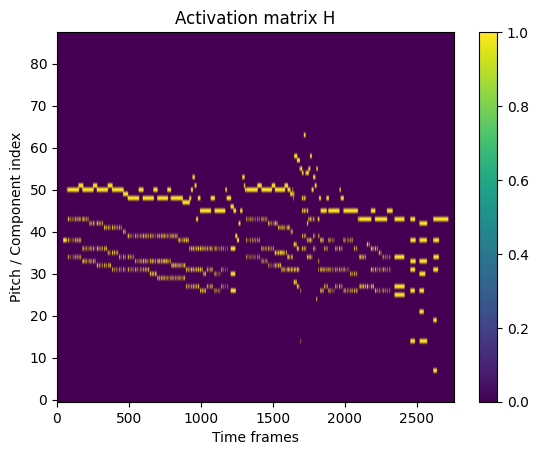

In [502]:
# 20 ms frames (matches typical STFT hop ~512 @ 44.1kHz)
dt = HOP / f_s
B, times = midi_to_binary_matrix(
    "Prelude-in-E-Minor-Nr-4.mid",
    dt=dt
)
print(B.shape,H4.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(B, aspect='auto', origin='lower')
#for idx in onsets:
#    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [503]:
def evaluate_results(H_et,H):
  #H_et - reference transcription of the piece
  #H - estimated transcription of the piece
  assert H_et.shape == H.shape
  P = 0
  R = 0
  F1 = 0
  TP = 0
  FP = 0
  FN = 0
  for i in range(H_et.shape[1]):
    TP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 1)
    FP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 0 and p == 1)
    FN += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 0)
  P = TP / (TP + FP)
  R = TP / (TP + FN)
  F1 = 2 * P * R / (P + R)
  return (P,R,F1)

In [504]:
print(H5.shape)

(88, 2781)


In [505]:
print(evaluate_results(H5[:,:B.shape[1]],B))

(0.7342271293375394, 0.4315379623621025, 0.5435861505225666)
